In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.chdir(r"C:\Users\cebal\OneDrive\Documentos\Grandes Bases de Datos I")

In [2]:
data = pd.read_csv("recursos_humanos (1).csv")
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low
...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,support,low
14995,0.37,0.48,2,160,3,0,1,0,support,low
14996,0.37,0.53,2,143,3,0,1,0,support,low
14997,0.11,0.96,6,280,4,0,1,0,support,low


In [3]:
# Recodificación de las variables categóricas
data = pd.get_dummies(data, columns=["sales", "salary"], drop_first=True)
data.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,1,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,1,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,1,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,1,0,False,False,False,False,False,False,True,False,False,True,False


In [ ]:
2) Mediante un analisis exploratorio determine si la base de datos esta equilibrada

In [4]:
# Separación de los empleados
# 0: empleados que permanecieron en la empresa
# 1: empleados que abandonaron la empresa
E = data[data.left == 0]
S = data[data.left == 1]

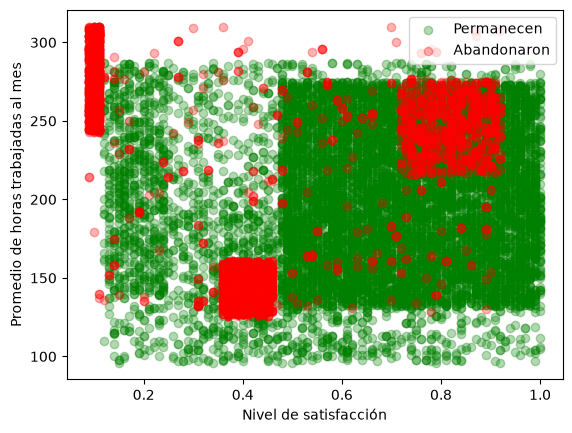

In [6]:
# Diagrama de dispersión
plt.scatter(E.satisfaction_level, E.average_montly_hours,
            color="green", label="Permanecen", alpha=0.3)

plt.scatter(S.satisfaction_level, S.average_montly_hours,
            color="red", label="Abandonaron", alpha=0.3)

plt.xlabel("Nivel de satisfacción")
plt.ylabel("Promedio de horas trabajadas al mes")
plt.legend()
plt.show()

In [7]:
# Frecuencia de las categorías
data.left.value_counts()

left
0    11428
1     3571
Name: count, dtype: int64

In [8]:
# Porcentaje de cada categoría
data.left.value_counts(normalize=True) * 100

left
0    76.191746
1    23.808254
Name: proportion, dtype: float64

In [ ]:
# Al observar el grafico podemos determinar que si existe un desequilibrio 
# ya que el 76.19% de los empleados permanecieron en la empresa y el 23.80%
# abandono su puesto en la empresa.

In [ ]:
3) Use el metodo de K vecinos mas Cercanos para generar un modelo predictivo

In [9]:
# 0 = Permanece, 1 = Abandona
data.left = data.left.astype(int)
data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,1,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,1,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,1,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,1,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,1,0,False,False,False,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,1,0,False,False,False,False,False,False,False,True,False,True,False
14995,0.37,0.48,2,160,3,0,1,0,False,False,False,False,False,False,False,True,False,True,False
14996,0.37,0.53,2,143,3,0,1,0,False,False,False,False,False,False,False,True,False,True,False
14997,0.11,0.96,6,280,4,0,1,0,False,False,False,False,False,False,False,True,False,True,False


In [10]:
y = data.left.values
x_data = data.drop(["left"], axis=1)

In [11]:
y

array([1, 1, 1, ..., 1, 1, 1], shape=(14999,))

In [12]:
x_data

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.38,0.53,2,157,3,0,0,False,False,False,False,False,False,True,False,False,True,False
1,0.80,0.86,5,262,6,0,0,False,False,False,False,False,False,True,False,False,False,True
2,0.11,0.88,7,272,4,0,0,False,False,False,False,False,False,True,False,False,False,True
3,0.72,0.87,5,223,5,0,0,False,False,False,False,False,False,True,False,False,True,False
4,0.37,0.52,2,159,3,0,0,False,False,False,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.40,0.57,2,151,3,0,0,False,False,False,False,False,False,False,True,False,True,False
14995,0.37,0.48,2,160,3,0,0,False,False,False,False,False,False,False,True,False,True,False
14996,0.37,0.53,2,143,3,0,0,False,False,False,False,False,False,False,True,False,True,False
14997,0.11,0.96,6,280,4,0,0,False,False,False,False,False,False,False,True,False,True,False


In [13]:
# Normalización
x = (x_data - np.min(x_data)) / (np.max(x_data) - np.min(x_data))
x

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,sales_RandD,sales_accounting,sales_hr,sales_management,sales_marketing,sales_product_mng,sales_sales,sales_support,sales_technical,salary_low,salary_medium
0,0.001226,0.001710,0.006452,0.506452,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.003226,0.000000
1,0.002581,0.002774,0.016129,0.845161,0.019355,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.000000,0.003226
2,0.000355,0.002839,0.022581,0.877419,0.012903,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.000000,0.003226
3,0.002323,0.002806,0.016129,0.719355,0.016129,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.003226,0.000000
4,0.001194,0.001677,0.006452,0.512903,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.003226,0.000000,0.0,0.003226,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14994,0.001290,0.001839,0.006452,0.487097,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.003226,0.0,0.003226,0.000000
14995,0.001194,0.001548,0.006452,0.516129,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.003226,0.0,0.003226,0.000000
14996,0.001194,0.001710,0.006452,0.461290,0.009677,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.003226,0.0,0.003226,0.000000
14997,0.000355,0.003097,0.019355,0.903226,0.012903,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.003226,0.0,0.003226,0.000000


In [14]:
# Bases de entrenamiento y prueba
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.30, random_state=1
)

In [15]:
# Modelo KNN (K vecinos más cercanos)
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x_train, y_train)

prediction = knn.predict(x_test)
print("Score: ", knn.score(x_test, y_test))

Score:  0.938


In [16]:
# Evaluación de distintos valores de K
resultados = []
for k in range(1, 21):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(x_train, y_train)
    prediction = knn.predict(x_test)
    score = knn.score(x_test, y_test)
    resultados.append([k, score])

# Tabla de resultados
tabla = pd.DataFrame(resultados, columns=["K", "Precision Global"])
tabla

,K,Precision Global
0,1,0.947333
1,2,0.944444
2,3,0.938000
3,4,0.942000
4,5,0.936222
5,6,0.942000
6,7,0.935333
7,8,0.938444
8,9,0.935111
9,10,0.938222


In [ ]:
# al conparar con diferentes k el modelo que tuvo mayor precision fue el k
# con valor igual a 1 ya que nos expresa el 94.73% de la presicion global

In [17]:
# Antes de continuar con el mapa de calor corremos el Modelo KNN con K óptimo
knn = KNeighborsClassifier(n_neighbors=1)
knn.fit(x_train, y_train)

prediction = knn.predict(x_test)
print("Score: ", knn.score(x_test, y_test))

Score:  0.9473333333333334


In [ ]:
4) Mapa de calor para la matriz de confusion 

In [18]:
y_pred = prediction
y_true = y_test

In [19]:
# Creación de la matriz de confusión
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_true, y_pred)
cm

array([[3239,  177],
       [  60, 1024]])

In [ ]:
# 3,239 Verdaderos negativos, empleados que permanecieron y fueron clasificados correctamente
# 60    Falsos negativos, empleados que abandonaron, pero fueron clasificados como permanentes
# 177   Falsos positivos, empleados que permanecieron, pero fueron clasificados como bajas
# 1,024 Verdaderos positivos. empleados que abandonaron y fueron identificados correctamente

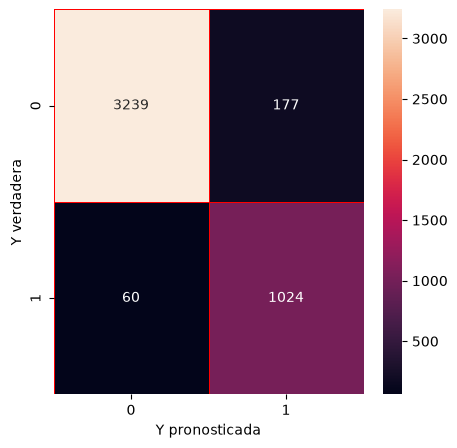

In [20]:
# Visualización de la matriz de confusión
import seaborn as sns

f, ax = plt.subplots(figsize=(5, 5))
sns.heatmap(cm, annot=True, linewidths=0.5,
            linecolor="red", fmt=".0f", ax=ax)
plt.xlabel("Y pronosticada")
plt.ylabel("Y verdadera")
plt.show()

In [21]:
# Cálculo de la precisión global
Correctos = cm[0,0] + cm[1,1]
Incorrectos = cm[0,1] + cm[1,0]

PrecisionGlobal = Correctos / (Correctos + Incorrectos)
PrecisionGlobal

np.float64(0.9473333333333334)

In [22]:
# precision de empleados que permanecen 
PrecisionPermanece = cm[0,0] / (cm[0,0] + cm[1,0])
PrecisionPermanece

np.float64(0.981812670506214)

In [23]:
# precision de empleados que abandonaron 
PrecisionAbandono = cm[1,1] / (cm[1,1] + cm[0,1])
PrecisionAbandono

np.float64(0.8526228143213989)

In [ ]:
5) Curva de ROC para el valor optimo K

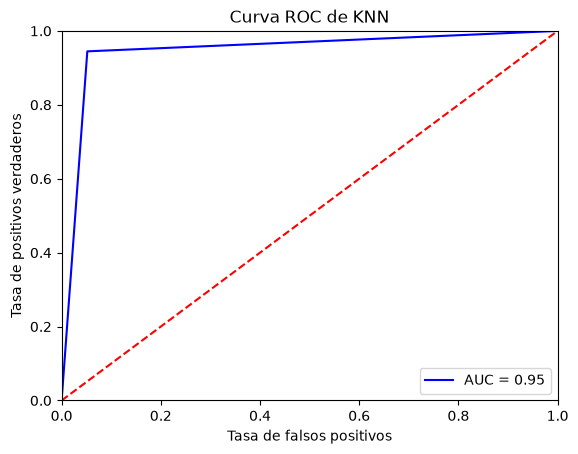

In [24]:
from sklearn.metrics import roc_curve
from sklearn.metrics import auc

y_scores = knn.predict_proba(x_test)

fpr, tpr, threshold = roc_curve(y_test, y_scores[:, 1])
# fpr = False positive rate, tpr = True positive rate

roc_auc = auc(fpr, tpr)

plt.title('Receiver Operating Characteristic')
plt.plot(fpr, tpr, 'b', label='AUC = %0.2f' % roc_auc)
plt.legend(loc='lower right')
plt.plot([0, 1], [0, 1], 'r--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('Tasa de positivos verdaderos')
plt.xlabel('Tasa de falsos positivos')
plt.title('Curva ROC de KNN')
plt.show()

In [ ]:
# existe aprox. un 95% de probabilidad de que el modelo asigne una puntuacion de riesgo de abandono 
# mayor a un empleado que efectivamente abandono que a uno que permanecio.